# 02 — Baselines: how good is "good" for this problem?

Before judging whether the paper's XGBoost model is any good, we need a floor
to compare it against. A model that gets R² = 0.95 sounds impressive, but if a
naive baseline already gets R² = 0.85 on the *same* target, the model is only
explaining a small sliver of genuinely hard variance.

**Crucial detail:** the paper's target variable is an *anomaly* —
`Temperature - ERA5_city_mean_temperature` — not the raw temperature. Reporting
R² on raw temperature would be almost meaningless here, since the ERA5
city-wide mean already explains most of the variance (synoptic weather swings
dwarf the local microclimate effect we actually care about). So every baseline
below predicts the *anomaly*, and we report both the anomaly-level metrics and
what they imply for the absolute temperature, for a fair comparison with the
paper's own reported numbers.

All baselines and the real model (notebook 03) use the **exact same
sensor-level train/test split** defined once in `src/urbansense_common.py`,
so the numbers here and in 03/04 are directly comparable.


In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

from urbansense_common import (
    load_data, sensor_level_split, split_day_night, regression_metrics,
    X_NAMES_AT_DAY, X_NAMES_AT_NIGHT, X_NAMES_RH_DAY, X_NAMES_RH_NIGHT,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

data = load_data()
train_sensor_ids, test_sensor_ids = sensor_level_split(data)
print(f"{len(train_sensor_ids)} train sensors, {len(test_sensor_ids)} test sensors")


27 train sensors, 12 test sensors


## 1. Define the baselines

- **Zero model** — predict anomaly = 0, i.e. just use the ERA5 city-mean
  value directly as the prediction for every sensor. This is the "don't even
  try to model microclimate" baseline.
- **Global mean anomaly** — predict the *training set's* mean anomaly for
  every test row (a single learned constant, no features at all).
- **Stratified mean anomaly** — predict the mean anomaly of the test row's
  land-cover x shade *stratum*, computed on the training sensors in that
  stratum. This uses the one piece of categorical metadata the stratified
  design is built around, but nothing continuous/spatial.
- **Linear regression** — the full static+dynamic feature set (same features
  XGBoost gets), but a plain linear model. Tests how much of the signal is
  linear vs. how much actually needs a nonlinear model like XGBoost.

Each is fit separately for day and night (since the feature lists and the
underlying physics differ), and separately for Ta and RH, exactly mirroring
how the paper itself splits the problem.


In [2]:
def fit_eval_baselines(data, target_col, X_names_day, X_names_night, train_ids, test_ids):
    day, night = split_day_night(data)
    results = []

    for period_name, df, X_names in [("day", day, X_names_day), ("night", night, X_names_night)]:
        train_mask = df["Sensor_ID"].isin(train_ids)
        test_mask = df["Sensor_ID"].isin(test_ids)

        y_train = df.loc[train_mask, target_col]
        y_test = df.loc[test_mask, target_col]

        # --- zero model: anomaly prediction is always 0 ---
        pred_zero = np.zeros(len(y_test))

        # --- global mean anomaly, learned on train only ---
        global_mean = y_train.mean()
        pred_global_mean = np.full(len(y_test), global_mean)

        # --- stratified (landcover x shade) mean anomaly, learned on train only ---
        strata_means = df.loc[train_mask].groupby("strata")[target_col].mean()
        pred_stratified = df.loc[test_mask, "strata"].map(strata_means).fillna(global_mean).values

        # --- linear regression on the full feature set ---
        X_train = df.loc[train_mask, X_names]
        X_test = df.loc[test_mask, X_names]
        scaler = StandardScaler()
        X_train_norm = scaler.fit_transform(X_train.values)
        X_test_norm = scaler.transform(X_test.values)
        lr = LinearRegression().fit(X_train_norm, y_train)
        pred_lr = lr.predict(X_test_norm)

        for model_name, preds in [
            ("Zero model (predict 0 anomaly)", pred_zero),
            ("Global mean anomaly", pred_global_mean),
            ("Stratified (landcover x shade) mean", pred_stratified),
            ("Linear regression (full features)", pred_lr),
        ]:
            m = regression_metrics(y_test, preds)
            m.update({"period": period_name, "model": model_name, "n_test": len(y_test)})
            results.append(m)

    return pd.DataFrame(results)[["period", "model", "n_test", "RMSE", "MAE", "MBE", "R2"]]


## 2. Air temperature baselines


In [3]:
at_results = fit_eval_baselines(
    data, "temp_anom", X_NAMES_AT_DAY, X_NAMES_AT_NIGHT, train_sensor_ids, test_sensor_ids
)
at_results


,period,model,n_test,RMSE,MAE,MBE,R2
0,day,Zero model (predict 0 anomaly),9872,2.080925,1.616175,-0.873057,-0.213628
1,day,Global mean anomaly,9872,1.889448,1.464344,-0.044644,-0.000559
2,day,Stratified (landcover x shade) mean,9872,1.788464,1.378697,-0.006414,0.103536
3,day,Linear regression (full features),9872,1.696142,1.269412,0.138824,0.193699
4,night,Zero model (predict 0 anomaly),6501,1.222924,0.949326,0.002142,-0.000003
5,night,Global mean anomaly,6501,1.223292,0.949775,-0.030082,-0.000605
6,night,Stratified (landcover x shade) mean,6501,1.211994,0.940789,-0.046604,0.017792
7,night,Linear regression (full features),6501,1.228501,0.955215,-0.000853,-0.009145


## 3. Relative humidity baselines


In [4]:
rh_results = fit_eval_baselines(
    data, "rh_anom", X_NAMES_RH_DAY, X_NAMES_RH_NIGHT, train_sensor_ids, test_sensor_ids
)
rh_results


,period,model,n_test,RMSE,MAE,MBE,R2
0,day,Zero model (predict 0 anomaly),9872,9.482926,7.223655,1.203775,-0.016378
1,day,Global mean anomaly,9872,9.406565,7.178058,0.081524,-0.000075
2,day,Stratified (landcover x shade) mean,9872,8.737261,6.700467,0.000467,0.137178
3,day,Linear regression (full features),9872,7.910423,6.016274,-0.944556,0.292755
4,night,Zero model (predict 0 anomaly),6501,7.822238,5.762676,-0.639023,-0.006719
5,night,Global mean anomaly,6501,7.796247,5.757054,-0.049064,-0.000040
6,night,Stratified (landcover x shade) mean,6501,7.700070,5.764351,0.039537,0.024482
7,night,Linear regression (full features),6501,6.767709,5.249542,-0.518895,0.246420


## 4. Putting it in context

The paper reports, on the held-out sensors: **Ta R² = 0.95, RMSE = 1.0°C**
(day RMSE 1.2°C, night RMSE 0.7°C) and **RH R² = 0.92, RMSE = 5.1%**. Let's
plot RMSE for every baseline against those reported XGBoost numbers.


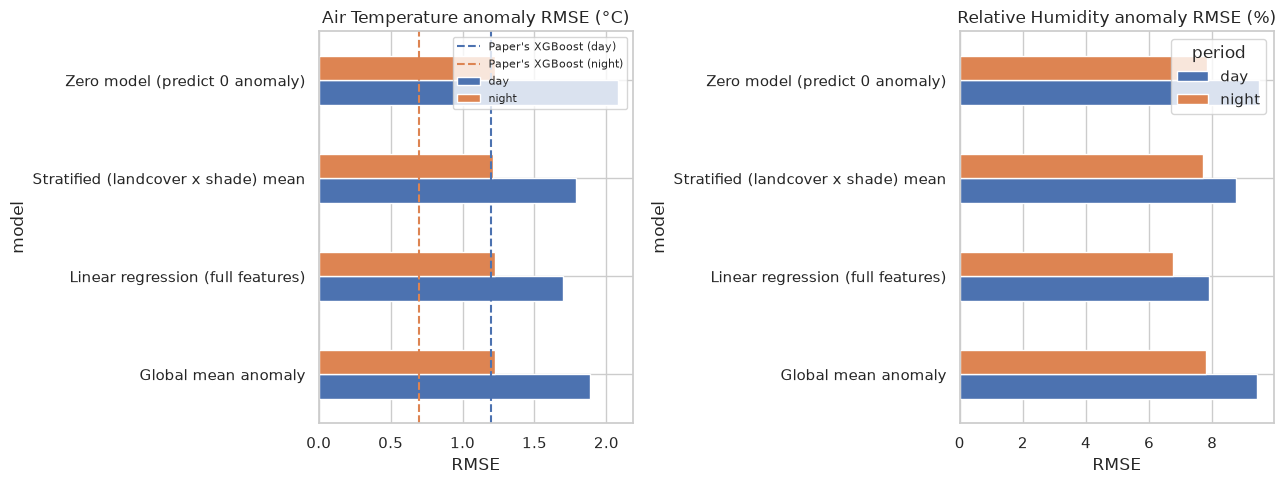

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, results, label, xgb_day, xgb_night in [
    (axes[0], at_results, "Air Temperature anomaly RMSE (°C)", 1.2, 0.7),
    (axes[1], rh_results, "Relative Humidity anomaly RMSE (%)", None, None),
]:
    pivot = results.pivot(index="model", columns="period", values="RMSE")
    pivot = pivot[["day", "night"]]
    pivot.plot(kind="barh", ax=ax)
    if xgb_day is not None:
        ax.axvline(xgb_day, color="C0", linestyle="--", label="Paper's XGBoost (day)")
        ax.axvline(xgb_night, color="C1", linestyle="--", label="Paper's XGBoost (night)")
        ax.legend(fontsize=8)
    ax.set(title=label, xlabel="RMSE")

plt.tight_layout()
plt.show()


## Takeaways

- The **zero model** and **global mean anomaly** baselines should perform
  almost identically to each other (the anomaly's unconditional mean is close
  to zero by construction), and both should be clearly worse than XGBoost —
  if they aren't much worse, that's a sign the "hard" part of this problem is
  smaller than it looks.
- The **stratified mean** baseline is the more interesting floor: it's a
  model-free version of exactly the information the paper's stratified
  sampling design is built to capture (land cover x shade). If XGBoost's
  improvement over this baseline is small, most of the paper's accuracy is
  coming from knowing which stratum a sensor is in, not from the richer
  continuous features (NDVI, SVF, distance-to-road, etc.) or from XGBoost's
  nonlinearity.
- **Linear regression** tells us how much of the remaining signal is linear.
  A big gap between linear regression and XGBoost means genuinely nonlinear
  interactions (e.g. the day/night reversal in the tree-canopy effect from
  notebook 01) matter; a small gap means XGBoost's main contribution here is
  convenience, not expressive power.

Next: [`03_model_reproduction.ipynb`](03_model_reproduction.ipynb) rebuilds
the authors' exact XGBoost pipeline on this same split, so we can see exactly
how much of a lift it gives over these baselines.
